Dataset Shape: (150, 4)
Target Classes: ['setosa' 'versicolor' 'virginica']

========== SVM ==========
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Log Loss: 0.11687890278264573

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]

========== Decision Tree ==========
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1 Score: 0.9333333333333333
Log Loss: 2.4029102259411435

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90     

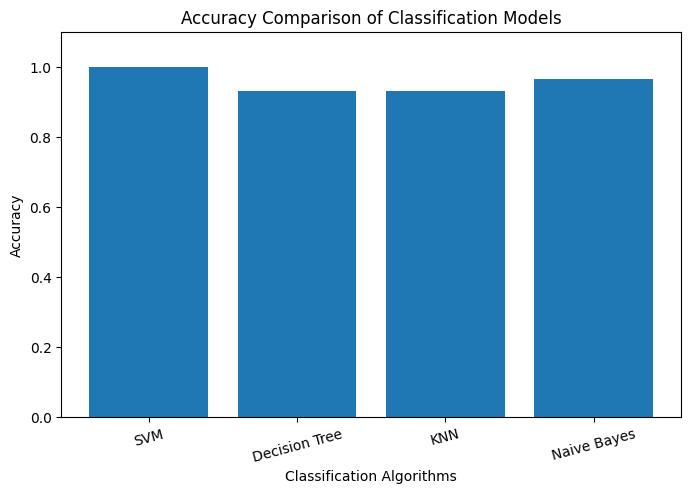

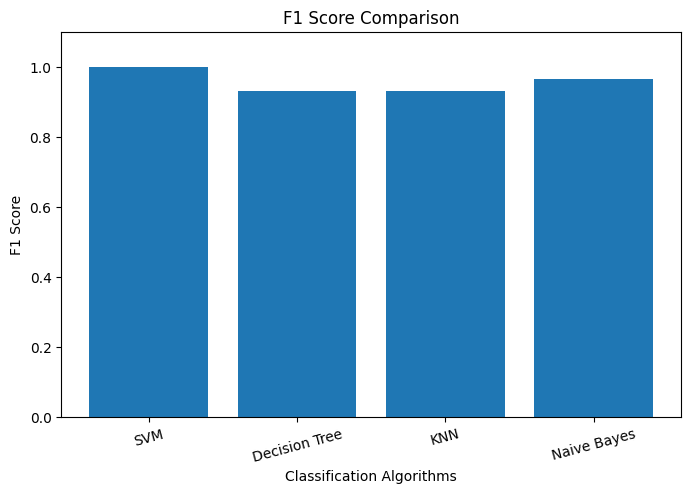

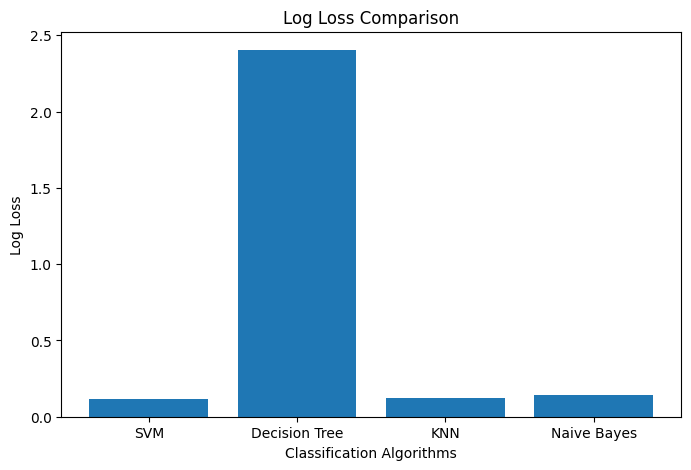

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix,
    classification_report
)

# 1. Load dataset
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset Shape:", X.shape)
print("Target Classes:", iris.target_names)

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Create classification models
models = {
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel='linear', probability=True, random_state=42)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Naive Bayes": GaussianNB()
}

# 4. Train and evaluate models
results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)

    # Prediction probabilities
    y_prob = model.predict_proba(X_test)

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average='weighted',
        zero_division=0
    )

    loss = log_loss(y_test, y_prob, labels=[0, 1, 2])

    results.append([
        name, accuracy, precision,
        recall, f1, loss
    ])

    print("\n==========", name, "==========")
    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1 Score:", f1)
    print("Log Loss:", loss)

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        target_names=iris.target_names,
        zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    print("Confusion Matrix:")
    print(cm)

# 5. Comparative analysis
result_df = pd.DataFrame(
    results,
    columns=[
        "Algorithm", "Accuracy",
        "Precision", "Recall",
        "F1 Score", "Log Loss"
    ]
)

print("\n========== MODEL COMPARISON ==========")
print(result_df.round(4).to_string(index=False))

# 6. Plot accuracy comparison
plt.figure(figsize=(8, 5))

plt.bar(
    result_df["Algorithm"],
    result_df["Accuracy"]
)

plt.xlabel("Classification Algorithms")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison of Classification Models")
plt.ylim(0, 1.1)
plt.xticks(rotation=15)
plt.show()
# 7. Plot F1-score comparison
plt.figure(figsize=(8, 5))
plt.bar(
result_df["Algorithm"],
result_df["F1 Score"]
)
plt.xlabel("Classification Algorithms")
plt.ylabel("F1 Score")
plt.title("F1 Score Comparison")
plt.ylim(0, 1.1)
plt.xticks(rotation=15)
plt.show()
# 8. Plot Log Loss comparison
plt.figure(figsize=(8, 5))
plt.bar(
result_df["Algorithm"],
result_df["Log Loss"]
)
plt.xlabel("Classification Algorithms")
plt.ylabel("Log Loss")
plt.title("Log Loss Comparison")
plt.show()